In [1]:
import pandas as pd
import numpy as np

orders = pd.read_csv('../data/olist_orders_dataset.csv')
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")

In [2]:
print("Orders dataset shape:", orders.shape)
print("Order items dataset shape:", order_items.shape)

Orders dataset shape: (99441, 8)
Order items dataset shape: (112650, 7)


In [3]:
sales_performance = pd.merge(
    orders, order_items, on='order_id', how='inner'
)



In [4]:
sales_performance.shape

(112650, 14)

In [5]:
sales_performance.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72


In [6]:
sales_performance.dtypes

order_id                             str
customer_id                          str
order_status                         str
order_purchase_timestamp             str
order_approved_at                    str
order_delivered_carrier_date         str
order_delivered_customer_date        str
order_estimated_delivery_date        str
order_item_id                      int64
product_id                           str
seller_id                            str
shipping_limit_date                  str
price                            float64
freight_value                    float64
dtype: object

In [7]:
date_columns = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'order_purchase_timestamp',
    'shipping_limit_date'
]
for col in date_columns:
    sales_performance[col] = pd.to_datetime(sales_performance[col], errors='coerce')

In [8]:
sales_performance.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
order_item_id                             int64
product_id                                  str
seller_id                                   str
shipping_limit_date              datetime64[us]
price                                   float64
freight_value                           float64
dtype: object

In [9]:
sales_performance['revenue'] = sales_performance['price']

In [10]:
sales_performance['revenue'].sum()

np.float64(13591643.700000001)

In [11]:
sales_performance['purchase_year'] = sales_performance['order_purchase_timestamp'].dt.year
sales_performance['purchase_month'] = sales_performance['order_purchase_timestamp'].dt.month



In [12]:
sales_performance[['order_purchase_timestamp', 'purchase_year', 'purchase_month']].head()

,order_purchase_timestamp,purchase_year,purchase_month
0,2017-10-02 10:56:33,2017,10
1,2018-07-24 20:41:37,2018,7
2,2018-08-08 08:38:49,2018,8
3,2017-11-18 19:28:06,2017,11
4,2018-02-13 21:18:39,2018,2


In [17]:
#How does revenue change from month to month?
monthly_revenue = (
    sales_performance
    .groupby(['purchase_year', 'purchase_month'])['revenue']
    .sum()
    .reset_index()
)
monthly_revenue.head()

,purchase_year,purchase_month,revenue
0,2016,9,267.36
1,2016,10,49507.66
2,2016,12,10.90
3,2017,1,120312.87
4,2017,2,247303.02


In [22]:
monthly_revenue['year_month'] = pd.to_datetime({
    'year': monthly_revenue['purchase_year'],
    'month': monthly_revenue['purchase_month'],
    'day': 1
})

In [23]:
monthly_revenue

,purchase_year,purchase_month,revenue,year_month
0,2016,9,267.36,2016-09-01
1,2016,10,49507.66,2016-10-01
2,2016,12,10.90,2016-12-01
3,2017,1,120312.87,2017-01-01
4,2017,2,247303.02,2017-02-01
5,2017,3,374344.30,2017-03-01
6,2017,4,359927.23,2017-04-01
7,2017,5,506071.14,2017-05-01
8,2017,6,433038.60,2017-06-01
9,2017,7,498031.48,2017-07-01


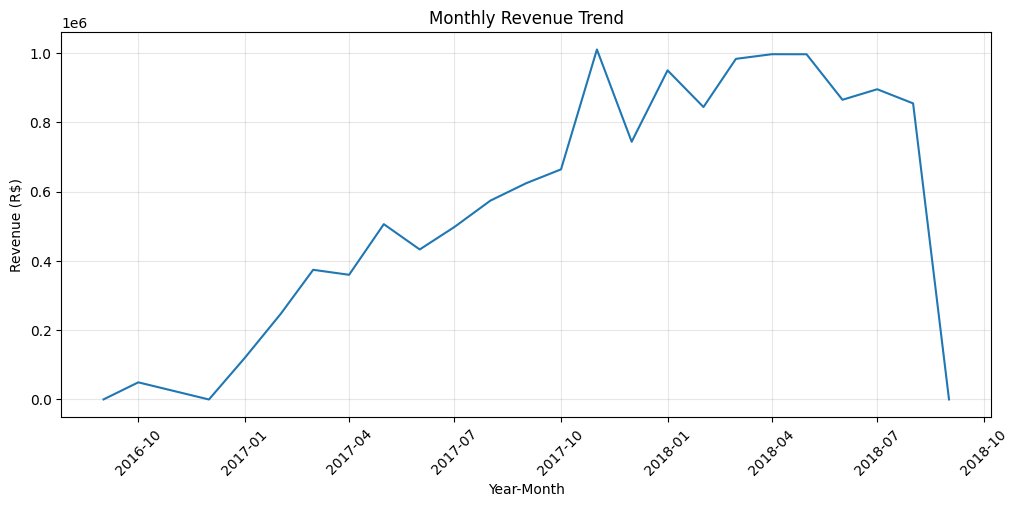

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.grid(True, alpha=0.3)
plt.plot(monthly_revenue['year_month'],monthly_revenue['revenue'])
plt.xlabel('Year-Month')
plt.ylabel('Revenue (R$)')
plt.title('Monthly Revenue Trend')
plt.xticks(rotation=45)
plt.show()

### Monthly Revenue Analysis — Key Findings

- Revenue showed an overall upward trend throughout 2017.
- November 2017 recorded the highest monthly revenue at R$1.01 million.
- Revenue remained relatively strong during the first eight months of 2018.
- A sharp decline occurred after August 2018, likely due to incomplete dataset coverage in the final months.

**Business Insight:** Olist demonstrated strong sales growth throughout the observed period. However, the incomplete data for September and October 2018 should be considered before drawing conclusions about the apparent revenue decline.

In [33]:
#monthly order volume
monthly_order_volume = (
    sales_performance
    .groupby(['purchase_year', 'purchase_month'])['order_id']
    .nunique()
    .reset_index()
)

monthly_order_volume = monthly_order_volume.rename(
    columns={'order_id': 'total_orders'}
)
monthly_order_volume

,purchase_year,purchase_month,total_orders
0,2016,9,3
1,2016,10,308
2,2016,12,1
3,2017,1,789
4,2017,2,1733
5,2017,3,2641
6,2017,4,2391
7,2017,5,3660
8,2017,6,3217
9,2017,7,3969


In [36]:
#average order value(AOV)
average_order_value = (
    monthly_revenue
    .merge(
        monthly_order_volume,
        on=['purchase_year', 'purchase_month'],
        how='inner'
    )
)
average_order_value['AOV'] = average_order_value['revenue'] / average_order_value['total_orders']
average_order_value

,purchase_year,purchase_month,revenue,year_month,total_orders,AOV
0,2016,9,267.36,2016-09-01,3,89.120000
1,2016,10,49507.66,2016-10-01,308,160.739156
2,2016,12,10.90,2016-12-01,1,10.900000
3,2017,1,120312.87,2017-01-01,789,152.487795
4,2017,2,247303.02,2017-02-01,1733,142.702262
5,2017,3,374344.30,2017-03-01,2641,141.743393
6,2017,4,359927.23,2017-04-01,2391,150.534182
7,2017,5,506071.14,2017-05-01,3660,138.270803
8,2017,6,433038.60,2017-06-01,3217,134.609450
9,2017,7,498031.48,2017-07-01,3969,125.480343


In [37]:
average_order_value.loc[average_order_value['AOV'].idxmax()]

purchase_year                    2016
purchase_month                     10
revenue                      49507.66
year_month        2016-10-01 00:00:00
total_orders                      308
AOV                        160.739156
Name: 1, dtype: object

In [39]:
average_order_value.loc[average_order_value['AOV'].idxmin()]

purchase_year                    2016
purchase_month                     12
revenue                          10.9
year_month        2016-12-01 00:00:00
total_orders                        1
AOV                              10.9
Name: 2, dtype: object

### AOV Analysis — Initial Findings

- Highest AOV: October 2016 (R$160.74), across 308 orders.
- Lowest AOV: December 2016 (R$10.90), based on only 1 order.
- November 2017 recorded the highest monthly revenue, but not the highest AOV.
- AOV and total revenue do not necessarily move together, as revenue is also influenced by order volume.

**Note:** Months with very few orders should be interpreted cautiously.

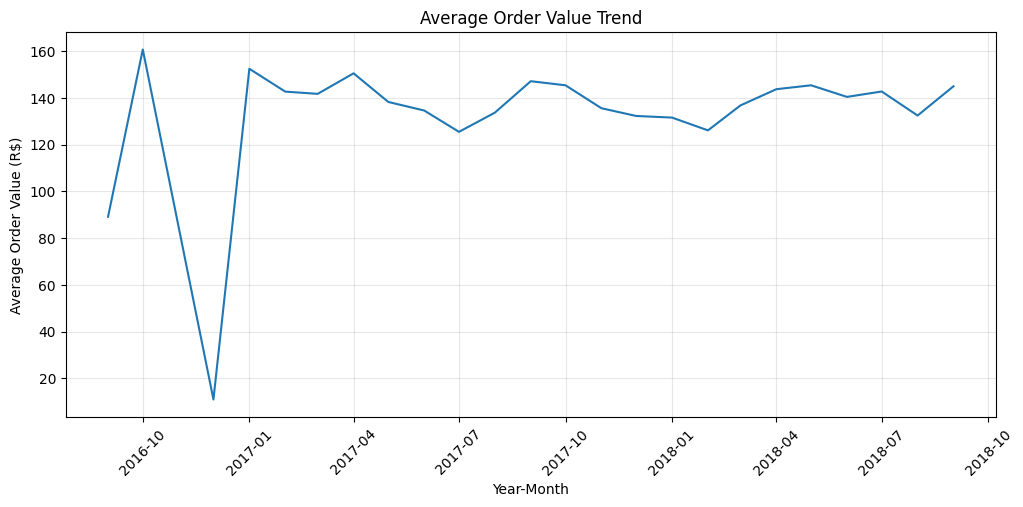

In [40]:
#AOV trend
plt.figure(figsize=(12, 5))
plt.grid(True, alpha=0.3)
plt.plot(average_order_value['year_month'], average_order_value['AOV'])
plt.xlabel('Year-Month')
plt.ylabel('Average Order Value (R$)')
plt.title('Average Order Value Trend')
plt.xticks(rotation=45)
plt.show()

### AOV Trend — Key Findings

- AOV fluctuated between approximately R$125 and R$152 throughout most of 2017 and 2018.
- October 2016 recorded the highest AOV (R$160.74).
- December 2016 recorded the lowest AOV (R$10.90), based on only one order.
- AOV remained relatively stable during 2017–2018.
- Months with very low order volumes require cautious interpretation.

**Business Insight:** Monthly revenue growth does not necessarily indicate an increase in average customer spending. Order volume and AOV should be evaluated together.

In [42]:
monthly_order_volume['year_month'] = pd.to_datetime({
    'year': monthly_order_volume['purchase_year'],
    'month': monthly_order_volume['purchase_month'],
    'day': 1
})

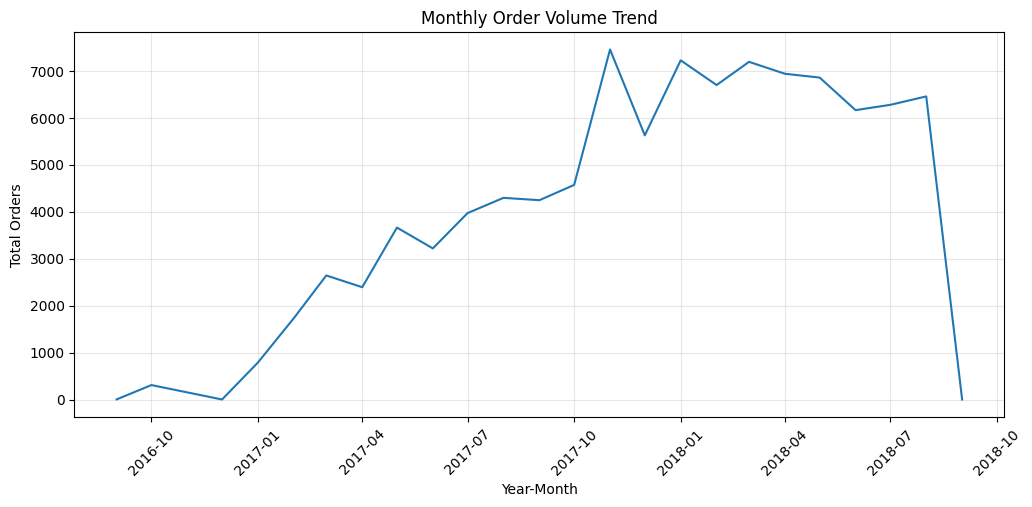

In [43]:
#Monthly Order Volume Trend
plt.figure(figsize=(12, 5))
plt.grid(True, alpha=0.3)
plt.plot(monthly_order_volume['year_month'], monthly_order_volume['total_orders'])
plt.xlabel('Year-Month')
plt.ylabel('Total Orders')
plt.title('Monthly Order Volume Trend')
plt.xticks(rotation=45)
plt.show()